# Bolted Wood Connection
**NDS 2024 Chapter 12 (ASD or LRFD) · yield limit equations · group action · geometry factor**

Single- or double-shear bolted connection with wood or steel side plates and load at any angle
to grain. Evaluates all yield modes (NDS Table 12.3.1A), the group action factor Cg (Eq. 12.3-1),
the geometry factor CΔ, and minimum end distance, edge distance, and spacing (NDS Tables 12.5.1A–D).

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_476d0793fd")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build 476d0793fd)")

structcalc 0.1.0 ready (build 476d0793fd)


In [2]:
#@title 1. Bolts and connection type
D = 0.625  #@param [0.5, 0.625, 0.75, 0.875, 1.0] {type:"raw"}
shear = "Double shear"  #@param ["Single shear", "Double shear"]
side_material = "Wood"  #@param ["Wood", "Steel plate"]
steel_grade = "ASTM A36 (Fu=58 ksi)"  #@param ["ASTM A36 (Fu=58 ksi)", "ASTM A572 Gr 50 (Fu=65 ksi)", "ASTM A992 (Fu=65 ksi)", "ASTM A653 Gr 33 sheet (Fu=45 ksi)", "ASTM A653 Gr 40 sheet (Fu=55 ksi)"]
Fyb = 45000  #@param {type:"number"}
#@markdown `D` in **in**, `Fyb` in **psi** (NDS Table 12A footnote: 45,000 psi for bolts).

In [3]:
#@title 2. Members (inches, psi, degrees)
species_main = "Douglas Fir-Larch"  #@param ["Douglas Fir-Larch", "Douglas Fir-Larch (North)", "Douglas Fir-South", "Hem-Fir", "Hem-Fir (North)", "Southern Pine", "Spruce-Pine-Fir", "Spruce-Pine-Fir (South)", "Western Woods", "Redwood (close grain)", "Eastern Softwoods", "Mixed Maple", "Red Oak", "Mixed Oak", "Yellow Poplar"]
t_main = 11.5  #@param {type:"number"}
w_main = 11.5  #@param {type:"number"}
E_main = 1300000  #@param {type:"number"}
theta_main = 50.0  #@param {type:"number"}
species_side = "Douglas Fir-Larch"  #@param ["Douglas Fir-Larch", "Douglas Fir-Larch (North)", "Douglas Fir-South", "Hem-Fir", "Hem-Fir (North)", "Southern Pine", "Spruce-Pine-Fir", "Spruce-Pine-Fir (South)", "Western Woods", "Redwood (close grain)", "Eastern Softwoods", "Mixed Maple", "Red Oak", "Mixed Oak", "Yellow Poplar"]
t_side = 1.5  #@param {type:"number"}
w_side = 7.25  #@param {type:"number"}
E_side = 1600000  #@param {type:"number"}
theta_side = 0.0  #@param {type:"number"}
softwood = True  #@param {type:"boolean"}
#@markdown t = thickness (bearing length), w = width (for Cg areas). For double shear, side values are for ONE side member.
#@markdown theta = angle between load and grain. Steel plates use E = 29,000,000 psi automatically.

In [4]:
#@title 3. Bolt pattern and geometry (inches)
n_rows = 2  #@param {type:"integer"}
n_per_row = 3  #@param {type:"integer"}
spacing = 2.5  #@param {type:"number"}
row_spacing = 4.75  #@param {type:"number"}
end_main = 6.0  #@param {type:"number"}
edge_main = 3.5  #@param {type:"number"}
stress_main = "compression"  #@param ["tension", "compression"]
loaded_edge_main = True  #@param {type:"boolean"}
end_side = 5.0  #@param {type:"number"}
edge_side = 1.25  #@param {type:"number"}
stress_side = "tension"  #@param ["tension", "compression"]
loaded_edge_side = True  #@param {type:"boolean"}
#@markdown *tension*: the bolt bears toward the member end. *loaded edge* applies to loads perpendicular to grain.

In [5]:
#@title 4. Factors and load
method = "ASD"  #@param ["ASD", "LRFD"]
CD = 1.6  #@param {type:"number"}
CM = 1.0  #@param {type:"number"}
Ct = 1.0  #@param {type:"number"}
lam = 1.0  #@param {type:"number"}
load = 13000.0  #@param {type:"number"}
#@markdown CD for ASD (1.6 wind/seismic, 1.15 snow, 1.25 construction, 1.0 occupancy live, 0.9 dead).
#@markdown lambda (time effect) for LRFD. load in lb: ASD-level for ASD, factored for LRFD.

In [6]:
#@title 5. Calculate
from structcalc.calcs import bolt_connection

out = bolt_connection.run(
    D=D, shear=shear, side_material=side_material, steel_grade=steel_grade, Fyb=Fyb,
    species_main=species_main, species_side=species_side,
    t_main=t_main, w_main=w_main, t_side=t_side, w_side=w_side,
    E_main=E_main, E_side=E_side, theta_main=theta_main, theta_side=theta_side,
    softwood=softwood, n_rows=n_rows, n_per_row=n_per_row, spacing=spacing,
    row_spacing=row_spacing, end_main=end_main, edge_main=edge_main,
    stress_main=stress_main, loaded_edge_main=loaded_edge_main,
    end_side=end_side, edge_side=edge_side, stress_side=stress_side,
    loaded_edge_side=loaded_edge_side,
    CD=CD, CM=CM, Ct=Ct, method=method, lam=lam, load=load,
)
out["report"].show()

Bolt diameter D,0.625,in
Bolt Fyb,"45,000",psi
Connection,"Double shear, wood side member(s)",
Main member,"Douglas Fir-Larch, 11.5 x 11.5 in",
Side member(s),"Douglas Fir-Larch, 1.5 x 7.25 in",
Load angle to grain: main / side,50 / 0.0,deg
Bolts,2 row(s) x 3 per row = 6,
Spacing in row / between rows,2.5 / 4.75,in
Main member end / edge distance,6 / 3.5,in
Side member end / edge distance,5 / 1.25,in
CD / CM / Ct,1.6 / 1 / 1,


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


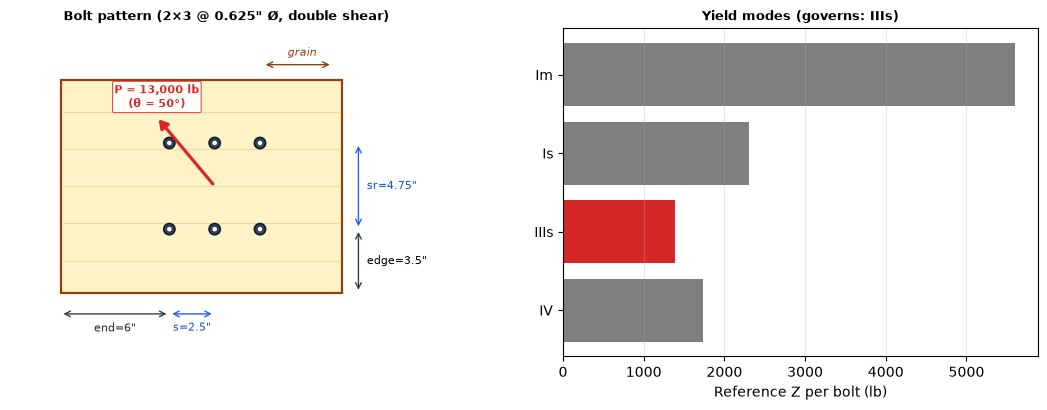

In [7]:
#@title 6. Bolt pattern and yield modes
fig = bolt_connection.plot(out)

In [8]:
#@title 7. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html("bolt_connection.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass